In [7]:
import numpy as np
import glob
import pickle
import sys
import matplotlib.pyplot as plt
plt.style.use("~/evanstyle.mplstyle")
sys.path.append("../Acdc/")
import Acdc 



# Using noise as a metric, look at proton data noise with its 5 day delayed pedestal calibration

In [2]:
#Structure of this dict:
#key: acdc number
#value: dict with the following keys
#   obj: Acdc object itself
#   config: configuration file path 
#   infiles: list of input data files for that board

#this set of boards is used in the July 2024 proton data at test-beam
acdcs = {44:{"obj":None, "config":"../configs/acdc44.yml", "infiles": [], "pedfiles": []}, \
	43:{"obj":None, "config":"../configs/acdc43.yml", "infiles": [], "pedfiles": []}}

#Configure some data filepaths
#you'll likely want to keep paths as we may be committing/pushing
#multiple paths. Just use a comment
#datadir = "../../data/20240701ProtonDataFTBF/"

#evans local path
datadir = "/Volumes/CODEDRIVE/FTBF/ProtonJune2024/"


In [ ]:
#Do not run if you are already reading prereduced data files. Skip to the next cell.

#load the waveforms into the events attribute
for acdc_num, a in acdcs.items():
	a["obj"] = Acdc.Acdc(a["config"])

	#the configuration is now parsed, so we can find which station id
	#in order to parse the filetag at the end of the data filenames. 
	bnum = a["obj"].c["station_id"]
	#find all the data files for this board
	a["infiles"] = glob.glob(datadir + f"raw/Raw_Proton*b{bnum}.txt")
	#find all the pedestal files for this board
	a["pedfiles"] = glob.glob(datadir + f"pedestals/Raw_test*b{bnum}.txt")


	#go file by file and save pre-reduced data for each file.
	#The machinery in the ACDC class can instead handle all files,
	# it is so resource and RAM intensive that I instead opt to save
	#a pre-reduced output file for each input file, looping individually. 
	for f in a["infiles"]:
		#the function can take a list of files, 
		#so I pass just the one we are working on
		a["obj"].load_raw_data_to_events([f]) 

		#loads root file containing linearity data, 
		#calibrates pedestals based on ADC/voltage and does
		#pedestal subtraction, and loads timebase calibration.
		#Within these pedfiles, it finds the closest file to our
		#events without using a future pedfile. 
		#a["obj"].calibrate_waveforms(a["pedfiles"])
		#a["obj"].write_events_to_file(f.replace(".txt", "_prereduced.p"))

		#the above is commented out so that we can break it out into steps and compare
		#noise before and after. 
		filetag = f.split("/")[-1].split(".")[0]
		a["obj"].calibrate_waveforms_with_checkpoints(a["pedfiles"], checkpoint_file=datadir + f"calibration-check/checkpoints_{filetag}.p", nevents=10)




Loading 1 of 1 files
Loading timebase data
Can't find the filepath for the calibration file: ../../data/calibrations/acdc44.root	
Loading pedestal data for file /Volumes/CODEDRIVE/FTBF/ProtonJune2024/pedestals/Raw_test_20240627_142501_b0.txt
Loading linearity data
Can't find the filepath for the calibration file: ../../data/calibrations/acdc44.root	
Calibrating pedestal data to convert to mV
Pedestal subtracting and converting to mV for all event waveforms
On event 0 of 10000, but limiting to 10
On event 1 of 10000, but limiting to 10
On event 2 of 10000, but limiting to 10
On event 3 of 10000, but limiting to 10
On event 4 of 10000, but limiting to 10
On event 5 of 10000, but limiting to 10
On event 6 of 10000, but limiting to 10
On event 7 of 10000, but limiting to 10
On event 8 of 10000, but limiting to 10
On event 9 of 10000, but limiting to 10
Reached the limit of 10 events. Stopping.
Saving checkpoint data to /Volumes/CODEDRIVE/FTBF/ProtonJune2024/calibration-check/checkpoints_/V

FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/CODEDRIVE/FTBF/ProtonJune2024/calibration-check/checkpoints_/Volumes/CODEDRIVE/FTBF/ProtonJune2024/raw/Raw_ProtonData_20240701_135251_b0.txt.txt'

In [5]:
#the above is commented out so that we can break it out into steps and compare
#noise before and after. 
filetag = f.split("/")[-1].split(".")[0]
output_dict = a["obj"].calibrate_waveforms_with_checkpoints(a["pedfiles"], checkpoint_file=datadir + f"calibration-check/checkpoints_{filetag}.p", nevents=10)

Loading pedestal data for file /Volumes/CODEDRIVE/FTBF/ProtonJune2024/pedestals/Raw_test_20240627_142501_b0.txt
Calibrating pedestal data to convert to mV
Pedestal subtracting and converting to mV for all event waveforms
On event 0 of 10000, but limiting to 10
On event 1 of 10000, but limiting to 10
On event 2 of 10000, but limiting to 10
On event 3 of 10000, but limiting to 10
On event 4 of 10000, but limiting to 10
On event 5 of 10000, but limiting to 10
On event 6 of 10000, but limiting to 10
On event 7 of 10000, but limiting to 10
On event 8 of 10000, but limiting to 10
On event 9 of 10000, but limiting to 10
Reached the limit of 10 events. Stopping.
Saving checkpoint data to /Volumes/CODEDRIVE/FTBF/ProtonJune2024/calibration-check/checkpoints_Raw_ProtonData_20240701_135251_b0.p


# Now process the Muon data, which is a little bit more diverse

In [ ]:
#Structure of this dict:
#key: acdc number
#value: dict with the following keys
#   obj: Acdc object itself
#   config: configuration file path 
#   infiles: list of input data files for that board

#this set of boards is used in the July 2024 proton data at test-beam
acdcs = {44:{"obj":None, "config":"../configs/acdc44.yml", "infiles": [], "pedfiles": []}, \
	43:{"obj":None, "config":"../configs/acdc43.yml", "infiles": [], "pedfiles": []}}

#Configure some data filepaths
#you'll likely want to keep paths as we may be committing/pushing
#multiple paths. Just use a comment
#datadir = "../../data/20240701ProtonDataFTBF/"

#evans local path
datadir = "/Volumes/CODEDRIVE/FTBF/ProtonJune2024/"


# Plotting comparisons

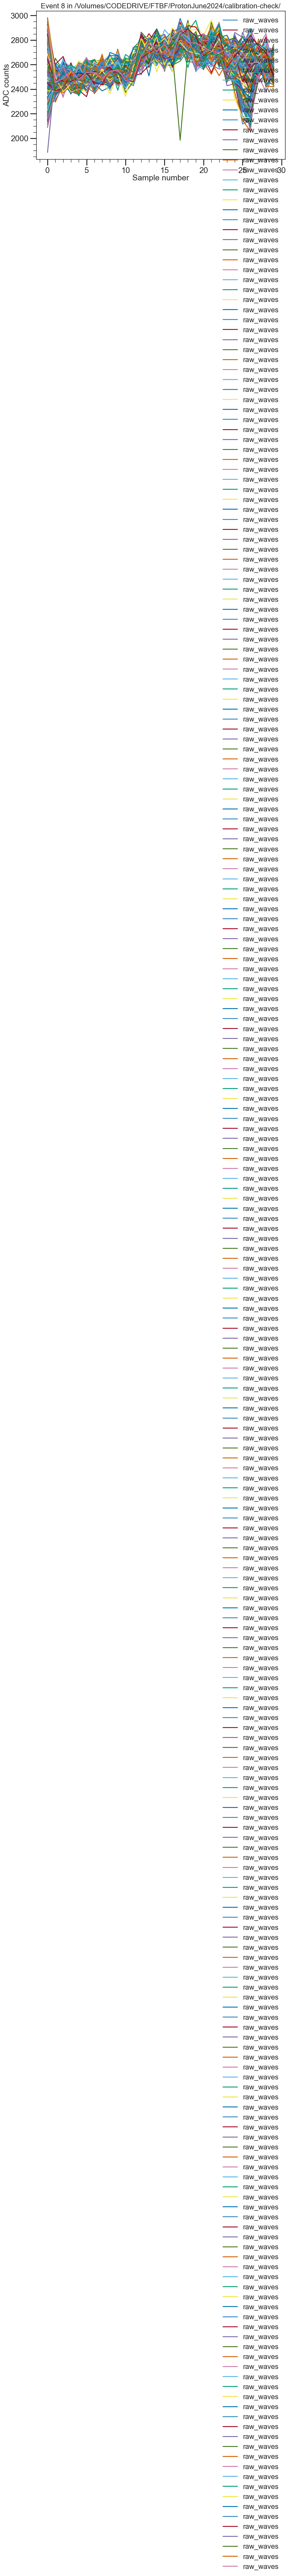



In [8]:
#NOT INTENDED IN THE LONG TERM. Just debugging some plots
proton_dir = "/Volumes/CODEDRIVE/FTBF/ProtonJune2024/calibration-check/"

proton_dd = pickle.load(open(proton_dir + "checkpoints_Raw_ProtonData_20240701_135251_b0.p", 'rb'))[0]


#pick a random event within the dataset to plot
event_num = np.random.randint(0, len(proton_dd['raw_waves']))

#overlay plot
fig, ax = plt.subplots()
key = 'raw_waves'
ts = np.array(range(len(proton_dd[key][event_num])))
ax.plot(ts, proton_dd[key][event_num], label=key)
ax.set_title(f"Event {event_num} in {proton_dir}")
ax.set_xlabel("Sample number")
ax.set_ylabel("ADC counts")
ax.legend()
plt.show()


fig, ax = plt.subplots()
key = 'linearity_corrected'
ts = np.array(range(len(proton_dd[key][event_num])))
ax.plot(ts, proton_dd[key][event_num], label=key)
key = 'fully_calibrated'
ts = np.array(range(len(proton_dd[key][event_num])))
ax.plot(ts, proton_dd[key][event_num], label=key)
ax.set_title(f"Event {event_num} in {proton_dir}")
ax.set_xlabel("Sample number")
ax.set_ylabel("[mV]")
ax.legend()
plt.show()
